# Comparing tTEM and diffTEM

In [20]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import plog

from anemone.experiment import *
from math import log10

In [21]:
from libaarhusxyz import GEX

In [146]:
gex = GEX("C:/Users/au646858/Downloads/TX11_3x3_1_turn.gex")
# gex = GEX(r"Z:\Projects_tTEM\2021_tTEM_NoerreVosborg\tTEM\Data\20210217_TX08_tTEM33_RC20_CalATV.gex")

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


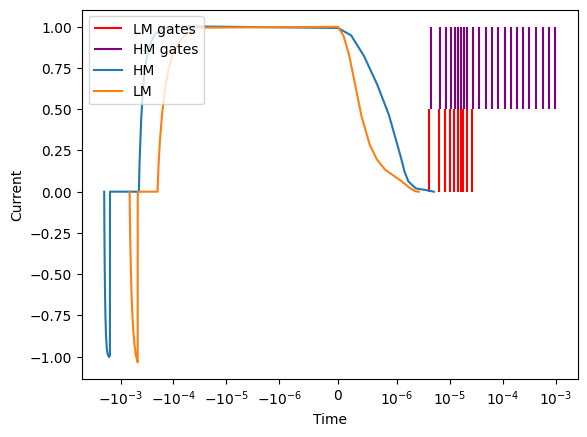

In [147]:
gex.plot()

In [148]:
lmgates = torch.from_numpy(gex.gate_times('Channel1')[:,0])
hmgates = torch.from_numpy(gex.gate_times('Channel2')[:,0])

LMwv = Waveform(gex.General['WaveformLMPoint'][:, 0], gex.General['WaveformLMPoint'][:, 1])
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

In [149]:
from anemone.transforms import invLaplace

class DualMomentLaplace:
    def __init__(self, source, receiver, times, filterfunc, waveforms):
        self.source = source
        self.receiver = receiver
        self.times = times
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times[0].device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times[0].device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)
                
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times[0].device)
        self.waveforms = waveforms
        self.tmin = min(self.times[0].min(), self.times[1].min())
        self.tmax = max(self.times[0].max(), self.times[1].max())

        n_dec = int(self.tmax/self.tmin)
        print(n_dec)
        self.teval = torch.logspace(log10(self.tmin), log10(self.tmax), 301, device=times[0].device)

        self.filterfunc = filterfunc
        self.device = times[0].device
        self.waveforms = []
        for waveform in waveforms:
            if waveform is not None:
                if waveform.time.max()<self.tmin:
                    self.tmin += -waveform.time.max()
                self.tmax += -waveform.time.min()
                waveform.time = waveform.time.to(self.device)
                waveform.amplitude = waveform.amplitude.to(self.device)
                waveform.d2wdt2 = waveform.d2wdt2.to(self.device)
            self.waveforms.append(waveform)
        


    def forward(self):
        def wvlngth_integrand(wave_length):
            lmb = wave_length[None,:,None]
            
            def laplace_integrand(s):
                """ Hz from horizontal electric dipole. """
                omega = -1j*s
                tmp_u0 = u0(omega, lmb)
                cRTE = rte(self.sigma, self.thick, omega, lmb)
                intg = torch.exp(-tmp_u0*self.pfield_dz)+cRTE*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
                intg /= -1j*omega

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                return torch.squeeze(intg/c.fourpi)
            cbft = invLaplace(laplace_integrand, n_coefficients=8)
            resp = cbft(self.teval)
            return resp
        
        hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(self.rmin, self.rmax), device=self.device)
        dbdt = integrate_around_loop(self.source, self.receiver, hkl1)
        t = self.teval
        cbft = CubicSpline(t,dbdt.real, transform=torch.log10)
        
        dbdts = []
        for i in range(2):
            t = self.times[i]
            t_eval = t[:, None] - self.waveforms[i].time[None, :]
            resp_step = cbft(t_eval)
            dbdt = resp_step @ self.waveforms[i].d2wdt2
            dbdts.append(dbdt.T)
        return torch.concatenate(dbdts).T

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
        if sigma.ndim > thickness.ndim:
            thickness = thickness[:, None]
        self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]
        return self.forward().real*c.mu0

In [150]:
class DualMoment:
    def __init__(self, source, receiver, times, filterfunc, waveforms):
        self.source = source
        self.receiver = receiver
        self.times = times
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times[0].device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times[0].device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)
                
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times[0].device)
        self.waveforms = waveforms
        self.tmin = min(self.times[0].min(), self.times[1].min())
        self.tmax = max(self.times[0].max(), self.times[1].max())

        self.filterfunc = filterfunc
        self.device = times[0].device
        self.waveforms = []
        for waveform in waveforms:
            if waveform is not None:
                if waveform.time.max()<self.tmin:
                    self.tmin += -waveform.time.max()
                self.tmax += -waveform.time.min()
                waveform.time = waveform.time.to(self.device)
                waveform.amplitude = waveform.amplitude.to(self.device)
                waveform.d2wdt2 = waveform.d2wdt2.to(self.device)
            self.waveforms.append(waveform)


    def forward(self):
        def frq_integrand(f):
            omega = c.twopi*f[None,:,None]

            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)
                cRTE = rte(self.sigma, self.thick, omega, lmb)
                intg = torch.exp(-tmp_u0*self.pfield_dz)+cRTE*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
                intg /= -1j*omega

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                return torch.squeeze(intg/c.fourpi)

            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(self.rmin, self.rmax), device=self.device)
            return integrate_around_loop(self.source, self.receiver, hkl1)#/1j

        ift = invFourier(frq_integrand, smp_per_decade=16)
        t,dbdt=ift.range(self.tmin, self.tmax)
        cbft = CubicSpline(t,dbdt.real, transform=torch.log10)
        
        dbdts = []
        for i in range(2):
            t = self.times[i]
            t_eval = t[:, None] - self.waveforms[i].time[None, :]
            resp_step = cbft(t_eval)
            dbdt = resp_step @ self.waveforms[i].d2wdt2
            dbdts.append(dbdt.T)
        return torch.concatenate(dbdts).T

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
        if sigma.ndim > thickness.ndim:
            thickness = thickness[:, None]
        self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]
        return self.forward().real*c.mu0
    

In [151]:

recfilters = FilterChain([
    # ButterworthFilter(6.79e5),
    ButterworthFilter(4.2e5),
    # ButterworthFilter(4.2e5)
])

tx = Loop.square(3, z=0.97)
rx = Receiver(y=9, z=0.43)

fwr = DualMoment(tx, rx, [lmgates, hmgates], recfilters, [LMwv, HMwv])

C:\Users\au646858\AppData\Local\Temp\ipykernel_29564\2604986708.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times[0].device)


In [152]:
#res = np.array([10, 200, 20])
res = np.array([200, 10, 50])
thick1 = np.linspace(0.1, 5, 25)

In [153]:
sigma = torch.from_numpy(1./res)
thick = torch.tensor([5, 10])
data = fwr(sigma, thick)

C:\Users\au646858\AppData\Local\Temp\ipykernel_29564\2604986708.py:66: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_29564\2604986708.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]


In [154]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
sigma = torch.from_numpy(1./res)[:, None]
thick = torch.from_numpy(thick_stack)

lgs = [plog.Log(np.log10(res), np.array([0, thk, thk+10]), np.array([thk,thk+10, 20]), 'rho', units='$\\Omega m$') for thk in thick1]

In [155]:
# plt.figure()
# plt.semilogy(np.abs(dbdt[0].numpy()), 'k')

C:\Users\au646858\AppData\Local\Temp\ipykernel_29564\2604986708.py:66: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_29564\2604986708.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]


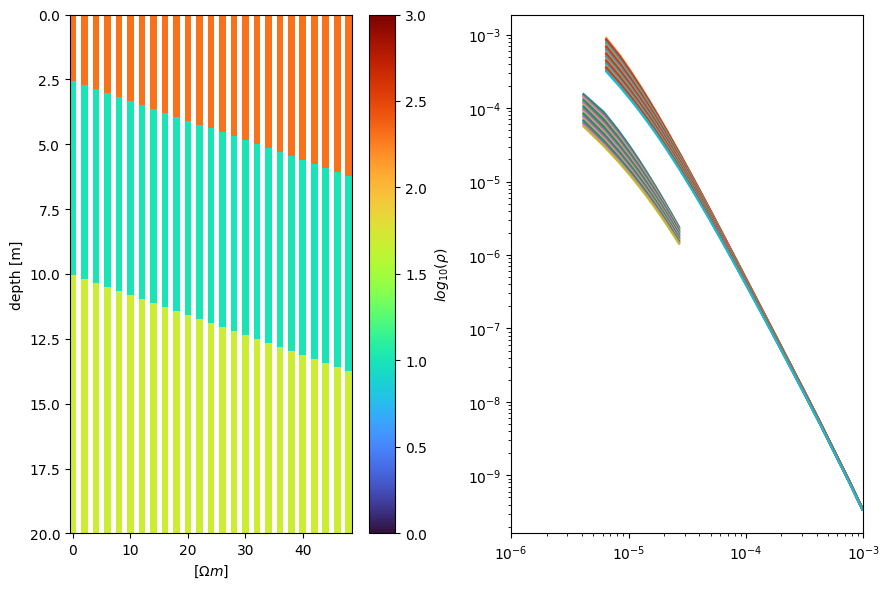

In [159]:
fig,axs = plt.subplots(1,2, figsize=(9,6))
for i,lg in enumerate(lgs):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([thick1[i], 10])
    dbdt = fwr(sigma, thick)

    axs[1].loglog(fwr.times[0].numpy(), dbdt[:len(fwr.times[0])].numpy()*3)
    axs[1].loglog(fwr.times[1].numpy(), dbdt[len(fwr.times[0]):].numpy()*30)
    ax,pcm=lg.plot(ax=axs[0], x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)

plt.colorbar(pcm, ax=ax, label='$log_{10}\\left(\\rho\\right)$', format='%.1f')
ax.set_ylabel('depth [m]')

axs[1].set_xlim(1e-6, 1e-3)
plt.tight_layout()